<a href="https://colab.research.google.com/github/OkBruh1234/HW-Model/blob/main/HI%26SM_correlation_best_run.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1. Data Loading: Pre-processed Heat Index (HI) Dataset

This notebook analyzes the correlation between Heat Index (HI) and Soil Moisture (SM) for Delhi-NCR.

We begin by loading a pre-processed dataset, `final_dataset(2).csv`. This file contains the daily Heat Index (`HI_C`), which was calculated for a separate heatwave forecasting project.

-   **HI Calculation**: Heat Index was derived using the Rothfusz regression formula.
-   **Data Source**: The temperature and humidity data used for the HI calculation were sourced from the **ERA5-Land dataset**, ensuring consistency with the meteorological data used later in this notebook.
-   **Target Variable**: The primary variable from this file is `HI_C`, which will be our target for the correlation analysis.

In [2]:
# Load the pre-processed Heat Index dataset
import pandas as pd

hi_dataset_path = '/content/drive/MyDrive/Datasets/final_dataset(2).csv'
hi = pd.read_csv(hi_dataset_path)

# Prepare the 'date' column for merging
# We convert 'valid_time' to a datetime object and normalize it to midnight, creating a clean daily key.
hi['date'] = pd.to_datetime(hi['valid_time'], errors='coerce').dt.normalize()

# Select only the necessary columns and remove any rows with invalid dates
hi = hi[['date', 'HI_C', 'is_heatwave', 'month']].dropna(subset=['date'])

print("Successfully loaded the pre-processed HI dataset.")
print(f"Date range: {hi['date'].min().date()} to {hi['date'].max().date()}")
hi.head()

Successfully loaded the pre-processed HI dataset.
Date range: 1965-03-01 to 2025-07-16


,date,HI_C,is_heatwave,month
0,1965-03-01,25.345643,0,3
1,1965-03-02,25.595259,0,3
2,1965-03-03,24.871519,0,3
3,1965-03-04,24.226448,0,3
4,1965-03-05,25.541846,0,3


In [3]:
# import requests
# import pandas as pd

# url = "https://archive-api.open-meteo.com/v1/archive?latitude=28.6519&longitude=77.2315&start_date=1965-01-01&end_date=2025-07-18&hourly=temperature_2m,relative_humidity_2m,soil_moisture_0_to_7cm&models=era5_land&timezone=auto"

# response = requests.get(url)
# data = response.json()

# # Convert hourly data to DataFrame
# df = pd.DataFrame(data['hourly'])
# print(df.head())
# df.shape

# --- Cell 3 (Fixed) ---
import requests
import pandas as pd
import os

# Save path
hourly_file = "hourly_openmeteo.csv"

if os.path.exists(hourly_file):
    print("✅ Loading hourly data from local CSV...")
    df = pd.read_csv(hourly_file, parse_dates=["time"], index_col="time")
else:
    print("🌐 Fetching hourly data from Open-Meteo API...")
    url = (
        "https://archive-api.open-meteo.com/v1/archive"
        "?latitude=28.6519&longitude=77.2315"
        "&start_date=1965-01-01&end_date=2025-07-18"
        "&hourly=temperature_2m,relative_humidity_2m,soil_moisture_0_to_7cm"
        "&models=era5_land&timezone=auto"
    )
    response = requests.get(url)
    data = response.json()

    if "error" in data:
        raise ValueError(f"API Error: {data['reason']}")

    df = pd.DataFrame(data["hourly"])
    df["time"] = pd.to_datetime(df["time"])
    df = df.set_index("time")

    # Save for reuse
    df.to_csv(hourly_file)
    print("💾 Saved hourly data to CSV for reuse.")

print(df.head())
print(df.shape)



🌐 Fetching hourly data from Open-Meteo API...
💾 Saved hourly data to CSV for reuse.
                     temperature_2m  relative_humidity_2m  \
time                                                        
1965-01-01 00:00:00            12.4                    66   
1965-01-01 01:00:00            11.9                    69   
1965-01-01 02:00:00            11.3                    73   
1965-01-01 03:00:00            10.8                    76   
1965-01-01 04:00:00            10.2                    79   

                     soil_moisture_0_to_7cm  
time                                         
1965-01-01 00:00:00                   0.077  
1965-01-01 01:00:00                   0.077  
1965-01-01 02:00:00                   0.077  
1965-01-01 03:00:00                   0.077  
1965-01-01 04:00:00                   0.077  
(530736, 3)


In [4]:
# Code cell 4

# This one cell replaces the old resampling, date creation, and summer filtering cells.

# Step 1: Resample the hourly ERA5 data to a daily frequency using the mean.
era_daily = df.resample('D').mean()

# Step 2: Create a clean 'date' column for merging.
era_daily['date'] = era_daily.index.normalize()

# Step 3: Filter for the relevant heatwave season (March-July).
era_daily['month'] = era_daily.index.month
era_summer = era_daily[era_daily['month'].isin([3, 4, 5, 6, 7])].copy()

print("✅ Successfully processed ERA5 data.")
print("   - Resampled to daily frequency.")
print("   - Filtered for summer months (March-July).")
era_summer.head()

✅ Successfully processed ERA5 data.
   - Resampled to daily frequency.
   - Filtered for summer months (March-July).


,temperature_2m,relative_humidity_2m,soil_moisture_0_to_7cm,date,month
time,,,,,
1965-03-01,18.512500,33.500000,0.070167,1965-03-01,3
1965-03-02,18.825000,32.375000,0.069583,1965-03-02,3
1965-03-03,18.354167,30.333333,0.069500,1965-03-03,3
1965-03-04,20.166667,27.833333,0.069292,1965-03-04,3
1965-03-05,21.237500,31.083333,0.068792,1965-03-05,3


In [5]:
#Code cell 5 - according to previous flow Code cell 8, 4,5,6,7 are deleted

# --- Pre-Merge Sanity Checks ---

# We are merging 'hi' and 'era_summer', so we check those two directly.
print("Checking for duplicate dates...")
print(f"HI duplicated dates: {hi['date'].duplicated().sum()}")
print(f"ERA summer duplicated dates: {era_summer['date'].duplicated().sum()}\n")

print("Checking number of shared dates...")
shared_dates = len(set(hi['date']).intersection(set(era_summer['date'])))
print(f"Found {shared_dates} shared summer dates for the merge.")


Checking for duplicate dates...
HI duplicated dates: 0
ERA summer duplicated dates: 0

Checking number of shared dates...
Found 9318 shared summer dates for the merge.


In [6]:
# Code cell 6 - acc. to previous flow this is 9

# --- Merge the Datasets for Summer Analysis ---

# We only need the key columns from era_summer.
era_to_merge = era_summer[['date', 'soil_moisture_0_to_7cm']].copy()

# The 'hi' dataset already contains month info, so we can filter it for summer.
hi_summer = hi[hi['month'].isin([3, 4, 5, 6, 7])].copy()

# Perform the single, final merge.
merged_summer = pd.merge(hi_summer, era_to_merge, on='date', how='inner')

print("✅ Successfully merged HI and ERA5 summer datasets.")
print(f"Final merged dataset shape: {merged_summer.shape}")
merged_summer.head()


✅ Successfully merged HI and ERA5 summer datasets.
Final merged dataset shape: (9318, 5)


,date,HI_C,is_heatwave,month,soil_moisture_0_to_7cm
0,1965-03-01,25.345643,0,3,0.070167
1,1965-03-02,25.595259,0,3,0.069583
2,1965-03-03,24.871519,0,3,0.069500
3,1965-03-04,24.226448,0,3,0.069292
4,1965-03-05,25.541846,0,3,0.068792


In [7]:
#Code cell 7, acc. to new flow, original flow - code cell 13
from scipy.stats import pearsonr, spearmanr
import numpy as np

def corr_report(df, xcol='HI_C', ycol='soil_moisture_0_to_7cm', label='ALL'):
    d = df[[xcol, ycol]].dropna()
    pr, pp = pearsonr(d[xcol], d[ycol])
    sr, sp = spearmanr(d[xcol], d[ycol])
    print(f"[{label}] Pearson r={pr:.3f}, p={pp:.2e} | Spearman r={sr:.3f}, p={sp:.2e} | n={len(d)}")

corr_report(merged_summer,    label='ALL DAYS')
corr_report(merged_summer, label='SUMMER')

[ALL DAYS] Pearson r=0.186, p=1.25e-73 | Spearman r=0.117, p=9.65e-30 | n=9318
[SUMMER] Pearson r=0.186, p=1.25e-73 | Spearman r=0.117, p=9.65e-30 | n=9318


In [8]:
#Code cell 8 acc, to new review, for old one this is code cell 14
from scipy.stats import pearsonr
import numpy as np

def lag_corr(df, x='HI_C', y='soil_moisture_0_to_7cm', maxlag=7, label='ALL'):
    print(f"[{label}] Lag correlations (HI → SM):")
    d = df[[x, y]].dropna().copy().reset_index(drop=True)
    for lag in range(0, maxlag+1):
        x_series = d[x].shift(lag)
        aligned = d[[y]].copy()
        aligned[x] = x_series
        aligned = aligned.dropna()
        if len(aligned) > 10:
            r, p = pearsonr(aligned[x], aligned[y])
            print(f"  lag={lag} days: r={r:.3f}, p={p:.2e}, n={len(aligned)}")
        else:
            print(f"  lag={lag} days: insufficient data")

lag_corr(merged_summer,    label='ALL DAYS',   maxlag=7)
lag_corr(merged_summer, label='SUMMER',     maxlag=7)


[ALL DAYS] Lag correlations (HI → SM):
  lag=0 days: r=0.186, p=1.25e-73, n=9318
  lag=1 days: r=0.206, p=8.57e-90, n=9317
  lag=2 days: r=0.242, p=7.65e-124, n=9316
  lag=3 days: r=0.277, p=7.55e-164, n=9315
  lag=4 days: r=0.306, p=1.80e-201, n=9314
  lag=5 days: r=0.330, p=4.01e-235, n=9313
  lag=6 days: r=0.347, p=2.85e-261, n=9312
  lag=7 days: r=0.361, p=6.64e-284, n=9311
[SUMMER] Lag correlations (HI → SM):
  lag=0 days: r=0.186, p=1.25e-73, n=9318
  lag=1 days: r=0.206, p=8.57e-90, n=9317
  lag=2 days: r=0.242, p=7.65e-124, n=9316
  lag=3 days: r=0.277, p=7.55e-164, n=9315
  lag=4 days: r=0.306, p=1.80e-201, n=9314
  lag=5 days: r=0.330, p=4.01e-235, n=9313
  lag=6 days: r=0.347, p=2.85e-261, n=9312
  lag=7 days: r=0.361, p=6.64e-284, n=9311


In [9]:
#Code cell 9 acc to new review, for old review this is code cell 15
import statsmodels.api as sm

def simple_reg(df):
    d = df[['HI_C','soil_moisture_0_to_7cm']].dropna().copy()
    d['sm_lag1'] = d['soil_moisture_0_to_7cm'].shift(1)
    d = d.dropna()
    y = d['soil_moisture_0_to_7cm']
    X = d[['sm_lag1','HI_C']]
    X = sm.add_constant(X)
    model = sm.OLS(y, X).fit()
    print(model.summary())

print("=== ALL DAYS ===")
simple_reg(merged_summer)
print("\n=== SUMMER ===")
simple_reg(merged_summer)


=== ALL DAYS ===
                              OLS Regression Results                              
Dep. Variable:     soil_moisture_0_to_7cm   R-squared:                       0.903
Model:                                OLS   Adj. R-squared:                  0.903
Method:                     Least Squares   F-statistic:                 4.339e+04
Date:                    Tue, 25 Nov 2025   Prob (F-statistic):               0.00
Time:                            07:08:48   Log-Likelihood:                 18656.
No. Observations:                    9317   AIC:                        -3.731e+04
Df Residuals:                        9314   BIC:                        -3.728e+04
Df Model:                               2                                         
Covariance Type:                nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------

In [10]:
# import requests
# import pandas as pd
# import os
# import numpy as np

# # --- Step 1: Fetch Hourly Data from Open-Meteo API ---
# # Full API URL
# url = "https://archive-api.open-meteo.com/v1/archive?latitude=28.6519&longitude=77.2315&start_date=1965-01-01&end_date=2025-07-18&daily=shortwave_radiation_sum,precipitation_sum,precipitation_hours&hourly=temperature_2m,relative_humidity_2m,soil_moisture_0_to_7cm,et0_fao_evapotranspiration&models=era5_land&timezone=auto"

# # File names for saving
# daily_file = "daily_data.csv"
# hourly_file = "hourly_data.csv"

# daily = None # Initialize daily and hourly DataFrames
# hourly = None

# if os.path.exists(daily_file) and os.path.exists(hourly_file):
#     print("✅ Loading from saved CSVs...")
#     try:
#         daily = pd.read_csv(daily_file, parse_dates=["time"], index_col="time")
#         hourly = pd.read_csv(hourly_file, parse_dates=["time"], index_col="time")
#         print("💾 Loaded both daily & hourly data from CSVs.")
#     except Exception as e:
#         print(f"❌ Error loading CSVs: {e}. Fetching from API instead.")
#         if os.path.exists(daily_file): os.remove(daily_file)
#         if os.path.exists(hourly_file): os.remove(hourly_file)


# if daily is None or hourly is None: # Fetch if loading failed or files didn't exist
#     print("🌐 Fetching from Open-Meteo API...")
#     response = requests.get(url)
#     data = response.json()

#     if "error" in data:
#         raise ValueError(f"API Error: {data['reason']}")

#     # Daily data
#     daily = pd.DataFrame(data["daily"])
#     daily["time"] = pd.to_datetime(daily["time"])
#     daily = daily.set_index("time")
#     daily.to_csv(daily_file)

#     # Hourly data
#     hourly = pd.DataFrame(data["hourly"])
#     hourly["time"] = pd.to_datetime(hourly["time"])
#     hourly = hourly.set_index("time")
#     hourly.to_csv(hourly_file)

#     print("💾 Saved both daily & hourly data as CSVs for future use.")

# # Quick check
# print("\nHourly sample:")
# print(hourly.head())
# print("\nDaily sample:")
# print(daily.head())

# # --- Step 2: Compute Heat Index (HI) from hourly T & RH ----
# def compute_heat_index(temp_c, rh):
#     """
#     Compute Heat Index in °C given temperature (°C) and relative humidity (%).
#     Formula is valid for T >= 27°C approx, else it approximates.
#     """
#     # Convert to Fahrenheit
#     T = (temp_c * 9/5) + 32
#     R = rh

#     # Handle potential NaN values
#     if pd.isna(T) or pd.isna(R):
#         return np.nan

#     HI_f = (-42.379 + 2.04901523*T + 10.14333127*R
#             - 0.22475541*T*R - 0.00683783*T*T
#             - 0.05481717*R*R + 0.00122874*T*T*R
#             + 0.00085282*T*R*R - 0.00000199*T*T*R*R)

#     # Convert back to Celsius
#     HI_c = (HI_f - 32) * 5/9
#     return HI_c

# # Apply HI computation to hourly dataset
# hourly["HI_C"] = hourly.apply(lambda row: compute_heat_index(row['temperature_2m'], row['relative_humidity_2m']), axis=1)

# # --- Step 3: Resample hourly → daily ---
# daily_hi = hourly["HI_C"].resample("D").mean()
# daily_sm = hourly["soil_moisture_0_to_7cm"].resample("D").mean()
# daily_et0 = hourly["et0_fao_evapotranspiration"].resample("D").mean()


# # --- Step 4: Create Clean Daily Dataset ---
# daily_clean = pd.DataFrame({
#     "precipitation_hours": daily["precipitation_hours"],  # already daily
#     "soil_moisture_0_to_7cm": daily_sm,                   # daily mean SM
#     "HI_C": daily_hi,                                     # daily mean HI
#     "et0": daily_et0                                      # daily mean ET0
# })

# # --- Step 5: Handle missing values & Finalize Daily Dataset ---

# # Interpolate soil moisture and ET0 (linear, limit direction both)
# # Perform interpolation on the DataFrame slice
# daily_clean["soil_moisture_0_to_7cm"] = daily_clean["soil_moisture_0_to_7cm"].interpolate(method="linear", limit_direction="both")
# daily_clean["et0"] = daily_clean["et0"].interpolate(method="linear", limit_direction="both")


# # Drop any rows where HI is missing (cannot interpolate HI safely)
# final_daily = daily_clean.dropna(subset=["HI_C"]).copy()


# print("\n✅ Final daily dataset (pre-NASA merge) ready. Columns:", final_daily.columns.tolist())
# print("Dataset shape:", final_daily.shape)

# print("\nSample of final daily dataset (pre-NASA merge):")
# print(final_daily.head())

# print("\nMissing values in final_daily (pre-NASA merge):")
# print(final_daily.isna().sum())

In [11]:
# import numpy as np

# # ---- Step 1: Compute Heat Index (HI) from hourly T & RH ----
# def compute_heat_index(temp_c, rh):
#     """
#     Compute Heat Index in °C given temperature (°C) and relative humidity (%).
#     Formula is valid for T >= 27°C approx, else it approximates.
#     """
#     # Convert to Fahrenheit
#     T = (temp_c * 9/5) + 32
#     R = rh

#     HI_f = (-42.379 + 2.04901523*T + 10.14333127*R
#             - 0.22475541*T*R - 0.00683783*T*T
#             - 0.05481717*R*R + 0.00122874*T*T*R
#             + 0.00085282*T*R*R - 0.00000199*T*T*R*R)

#     # Convert back to Celsius
#     HI_c = (HI_f - 32) * 5/9
#     return HI_c

# # Apply HI computation to hourly dataset
# hourly["HI_C"] = compute_heat_index(hourly["temperature_2m"], hourly["relative_humidity_2m"])

# # ---- Step 2: Resample to daily ----
# daily_hi = hourly["HI_C"].resample("D").mean()
# daily_sm = hourly["soil_moisture_0_to_7cm"].resample("D").mean()

# # ---- Step 3: Clean daily dataset ----
# daily_clean = pd.DataFrame({
#     "precipitation_hours": daily["precipitation_hours"],  # already daily
#     "soil_moisture_0_to_7cm": daily_sm,                   # daily mean SM
#     "HI_C": daily_hi                                      # daily mean HI
# })

# # ---- Step 4: Inspect ----
# print("✅ Clean daily dataset ready.")
# print("Columns kept:", daily_clean.columns.tolist())
# print("Shape:", daily_clean.shape)

# # Quick peek
# print("\nSample of daily_clean:")
# print(daily_clean.head())

# # ---- Step 5: Data quality report ----
# print("\n📊 Dataset info:")
# print(daily_clean.info())

# print("\n🔍 Missing values count per column:")
# print(daily_clean.isna().sum())

# print("\n✅ Non-null counts per column:")
# print(daily_clean.notna().sum())

In [12]:
# import numpy as np

# # ---- Step 1: Compute Heat Index (HI) from hourly T & RH ----
# def compute_heat_index(temp_c, rh):
#     """
#     Compute Heat Index in °C given temperature (°C) and relative humidity (%).
#     Formula is valid for T >= 27°C approx, else it approximates.
#     """
#     # Convert to Fahrenheit
#     T = (temp_c * 9/5) + 32
#     R = rh

#     HI_f = (-42.379 + 2.04901523*T + 10.14333127*R
#             - 0.22475541*T*R - 0.00683783*T*T
#             - 0.05481717*R*R + 0.00122874*T*T*R
#             + 0.00085282*T*R*R - 0.00000199*T*T*R*R)

#     # Convert back to Celsius
#     HI_c = (HI_f - 32) * 5/9
#     return HI_c

# # Apply HI computation to hourly dataset
# hourly["HI_C"] = compute_heat_index(hourly["temperature_2m"], hourly["relative_humidity_2m"])

# # ---- Step 2: Resample to daily ----
# daily_hi = hourly["HI_C"].resample("D").mean()
# daily_sm = hourly["soil_moisture_0_to_7cm"].resample("D").mean()

# # ---- Step 3: Clean daily dataset ----
# daily_clean = pd.DataFrame({
#     "precipitation_hours": daily["precipitation_hours"],  # already daily
#     "soil_moisture_0_to_7cm": daily_sm,                   # daily mean SM
#     "HI_C": daily_hi                                      # daily mean HI
# })

# # ---- Step 4: Inspect ----
# print("✅ Clean daily dataset ready.")
# print("Columns kept:", daily_clean.columns.tolist())
# print("Shape:", daily_clean.shape)

# # Quick peek
# print("\nSample of daily_clean:")
# print(daily_clean.head())

# # ---- Step 5: Data quality report ----
# print("\n📊 Dataset info:")
# print(daily_clean.info())

# print("\n🔍 Missing values count per column:")
# print(daily_clean.isna().sum())

# print("\n✅ Non-null counts per column:")
# print(daily_clean.notna().sum())


In [13]:
# # Code cell 19, meant to be deleted

# # --- Step E3: Handle missing values & prepare dataset ---

# # 1. Bring soil moisture to daily level (from hourly, using mean)
# soil_moisture_daily = hourly["soil_moisture_0_to_7cm"].resample("D").mean()

# # 2. Add soil moisture to daily_clean
# daily_clean["soil_moisture_0_to_7cm"] = soil_moisture_daily

# # 3. Check missing values before interpolation
# print("Missing values before filling:\n", daily_clean.isna().sum())

# # 4. Interpolate soil moisture (linear)
# daily_clean["soil_moisture_0_to_7cm"] = daily_clean["soil_moisture_0_to_7cm"].interpolate(method="linear")

# # 5. Drop any rows where HI is missing (cannot interpolate HI safely)
# daily_clean = daily_clean.dropna(subset=["HI_C"])

# # 6. Final check
# print("\nMissing values after filling:\n", daily_clean.isna().sum())

# print("\n✅ Final daily dataset sample:")
# print(daily_clean.head(10))

In [14]:
# #Code cell 20
# # --- Step E4: Resample ET0 (evapotranspiration) to daily ---
# et0_daily = hourly["et0_fao_evapotranspiration"].resample("D").mean()

# # Handle missing values (ET0 can have NaNs like we saw earlier)
# et0_daily = et0_daily.interpolate(limit_direction="both")

# print("✅ Daily ET0 sample:")
# print(et0_daily.head(), "\n")

# # --- Step E5: Merge all daily components ---
# final_daily = daily_clean.copy()  # from E2.1 (HI + precip_hours)

# # Add soil moisture (from E3)
# final_daily["soil_moisture"] = soil_moisture_daily  # already interpolated in E3

# # Add ET0 (from E4)
# final_daily["et0"] = et0_daily

# # Drop rows where HI is missing (edge cases)
# final_daily = final_daily.dropna(subset=["HI_C"])

# print("✅ Final daily dataset ready. Columns kept:", final_daily.columns.tolist())
# print("Dataset shape:", final_daily.shape)

# print("\nSample of final daily dataset:")
# print(final_daily.head())

In [15]:
# Code cell 21
# E4.1 - Fetch ET0 (Evapotranspiration) from 1981 onward

# Dropping this because of the fact that we are giving in a failed parameter ET0, fetches ET0 which is invalid

# import requests
# import pandas as pd

# # API call for ET0 only (daily, ERA5-Land)
# url_et0 = "https://archive-api.open-meteo.com/v1/archive?latitude=28.6519&longitude=77.2315&start_date=1981-01-01&end_date=2025-07-18&daily=shortwave_radiation_sum,precipitation_sum,precipitation_hours,et0_fao_evapotranspiration&hourly=temperature_2m,relative_humidity_2m,soil_moisture_0_to_7cm,et0_fao_evapotranspiration&models=era5_land&timezone=auto"


# print("🌐 Fetching ET0 (1981–present) from Open-Meteo...")
# response = requests.get(url_et0)
# data_et0 = response.json()

# if "error" in data_et0:
#     raise ValueError(f"API Error: {data_et0['reason']}")

# # Convert to DataFrame
# et0_df = pd.DataFrame(data_et0["daily"])
# et0_df["time"] = pd.to_datetime(et0_df["time"])
# et0_df = et0_df.set_index("time")

# print("✅ ET0 sample:")
# print(et0_df.head())

# # Save separately so we don’t lose it
# et0_df.to_csv("et0_data.csv")


### Appendix: Experimentation to Acquire Evapotranspiration (ET0) Data

The following cells document the attempts made to source historical daily evapotranspiration data after the initial API call to Open-Meteo for the ERA5-Land `et0_fao_evapotranspiration` parameter returned no data.

Our next attempt was to use the NASA POWER database, a standard source for agricultural meteorology data.

In [16]:
#Code cell 22

# Kept this for reference beacuse of the fact that instead of ET0 here, we fetched PET which is also invalid parameter, NASA POWER doesn't show this

import requests
import pandas as pd

lat, lon = 28.6139, 77.2090   # Delhi (example, replace with your lat/lon)
start, end = "19810101", "20201231"  # YYYYMMDD format

# NASA POWER endpoint for ET0
url = (
    f"https://power.larc.nasa.gov/api/temporal/daily/point"
    f"?start={start}&end={end}"
    f"&latitude={lat}&longitude={lon}"
    f"&community=AG"  # Agriculture community -> REQUIRED
    f"&parameters=PET" # Use PET instead of ET0
    f"&format=JSON"
)

print("🌐 Fetching PET from NASA POWER...")
resp = requests.get(url).json()

# Debug: keys in the JSON
# print(resp.keys())

# Extract PET safely
if "properties" in resp and "parameter" in resp["properties"] and "PET" in resp["properties"]["parameter"]:
    pet_dict = resp["properties"]["parameter"]["PET"]
    pet = pd.DataFrame.from_dict(pet_dict, orient="index", columns=["PET"])
    pet.index = pd.to_datetime(pet.index)
    print("✅ Sample PET data:")
    print(pet.head())
else:
    print("❌ Error response from NASA POWER:")
    print(resp)

🌐 Fetching PET from NASA POWER...
❌ Error response from NASA POWER:
{'header': 'The POWER Daily API failed to complete your request; please review the errors below and the POWER Docs (https://power.larc.nasa.gov/docs/).', 'messages': ['One of your parameters is incorrect: PET.']}


In [17]:
# # Code cell 23, Irrelevant and not needed for now
# # --- Step E7: Filter final_daily to match PET date range (1981 onwards) ---

# # Filter rows where the index (datetime) is on or after 1981-01-01
# final_daily_filtered = final_daily[final_daily.index >= '1981-01-01'].copy()

# print("✅ Final daily dataset filtered from 1981 onwards. Columns:", final_daily_filtered.columns.tolist())
# print("Dataset shape:", final_daily_filtered.shape)

# print("\nSample of filtered final daily dataset:")
# display(final_daily_filtered.head())

# print("\nMissing values after filtering:")
# print(final_daily_filtered.isna().sum())

In [18]:
# --- Step E6: Fetch and Merge PET data from NASA POWER ---

#Code cell 24- another failed fetch attempt with PET variablem, while even giving the latitude and longitude

# import requests
# import pandas as pd

# lat, lon = 28.6519, 77.2315
# start, end = 1981, 2025

# url = (
#     "https://power.larc.nasa.gov/api/temporal/daily/point?"
#     f"parameters=PET&community=AG&longitude={lon}&latitude={lat}"
#     f"&start={start}&end={end}&format=JSON"
# )

# print("🌐 Fetching PET (Potential ET) from NASA POWER...")
# resp = requests.get(url).json()

# # Check structure and create pet_df
# pet_df = pd.DataFrame() # Initialize empty DataFrame
# if "properties" in resp and "parameter" in resp["properties"]:
#     pet = resp["properties"]["parameter"]["PET"]
#     pet_df = pd.DataFrame.from_dict(pet, orient="index", columns=["PET"])
#     pet_df.index = pd.to_datetime(pet_df.index)
#     print("✅ Sample fetched PET data:\n", pet_df.head())
# else:
#     print("❌ Error response from NASA POWER:")
#     print(resp)
#     # Handle the error case - perhaps create an empty pet_df with datetime index
#     # or raise an error if PET data is critical
#     print("⚠️ Could not fetch PET data. Proceeding without PET.")
#     # Create an empty DataFrame with a datetime index to avoid merge errors
#     pet_df = pd.DataFrame(index=pd.to_datetime([]), columns=["PET"])


# # Ensure the index is datetime for final_daily
# if not isinstance(final_daily.index, pd.DatetimeIndex):
#     final_daily.index = pd.to_datetime(final_daily.index)

# # Merge final_daily with pet_df on their datetime indices
# # Use left merge to keep all rows from final_daily, filling PET with NaN where no match
# final_daily = final_daily.merge(pet_df, left_index=True, right_index=True, how='left')

# print("✅ Final daily dataset after merging PET. Columns:", final_daily.columns.tolist())
# print("Dataset shape:", final_daily.shape)

# print("\nSample of final daily dataset with PET:")
# print(final_daily.head())

# print("\nMissing values after merging PET:")
# print(final_daily.isna().sum())

In [19]:
# print(pet_df.keys())
# print(pet_df)
# print(resp)

In [20]:
# import requests
# import pandas as pd

# lat, lon = 28.6139, 77.2090   # Delhi
# start, end = "19810101", "20201231"

# url = (
#     f"https://power.larc.nasa.gov/api/temporal/daily/point"
#     f"?start={start}&end={end}"
#     f"&latitude={lat}&longitude={lon}"
#     f"&parameters=ETRS"
#     f"&community=AG"
#     f"&format=JSON"
# )

# print("🌐 Fetching Reference Evapotranspiration (ET0/ETRS) from NASA POWER...")
# resp = requests.get(url).json()

# if "properties" not in resp:
#     print("❌ Error response from NASA POWER:")
#     print(resp)
# else:
#     et0_dict = resp["properties"]["parameter"]["ETRS"]
#     et0 = pd.DataFrame.from_dict(et0_dict, orient="index", columns=["ET0"])
#     et0.index = pd.to_datetime(et0.index)
#     print("✅ Sample ET0 data:")
#     print(et0.head())

# Another failed attempt of trying to fetch RET variable, third consecutive failure of trying to fetch a variable which will give us the Evapotranspiration factor

# import requests
# import pandas as pd

# lat, lon = 28.6139, 77.2090   # Delhi
# start, end = "19810101", "20201231"

# url = (
#     f"https://power.larc.nasa.gov/api/temporal/daily/point"
#     f"?start={start}&end={end}"
#     f"&latitude={lat}&longitude={lon}"
#     f"&parameters=RET"
#     f"&community=AG"
#     f"&format=JSON"
# )

# print("🌐 Fetching Reference Evapotranspiration (ET0/RET) from NASA POWER...")
# resp = requests.get(url).json()

# if "properties" not in resp:
#     print("❌ Error response from NASA POWER:")
#     print(resp)
# else:
#     et0_dict = resp["properties"]["parameter"]["RET"]
#     et0 = pd.DataFrame.from_dict(et0_dict, orient="index", columns=["ET0"])
#     et0.index = pd.to_datetime(et0.index)
#     print("✅ Sample ET0 data:")
#     print(et0.head())



In [21]:
''' Another failure moment of trying to fetch a variable PET, so it now makes us understand that PET, RET, ET0 these variables which we thought would be
 present in Nasa Power they were actually not present and now we will try to get that index of Evapotranspiration, that will help us derive insightful meaning
 in our case
 '''

# import requests
# import pandas as pd

# lat, lon = 28.6519, 77.2315
# start, end = 1981, 2025

# url = (
#     "https://power.larc.nasa.gov/api/temporal/daily/point?"
#     f"parameters=PET&community=AG&longitude={lon}&latitude={lat}"
#     f"&start={start}&end={end}&format=JSON"
# )

# print("🌐 Fetching PET (Potential ET) from NASA POWER...")
# resp = requests.get(url).json()

# # Check structure
# if "properties" in resp and "parameter" in resp["properties"]:
#     pet = resp["properties"]["parameter"]["PET"]
#     pet_df = pd.DataFrame.from_dict(pet, orient="index", columns=["PET"])
#     pet_df.index = pd.to_datetime(pet_df.index)
#     print("✅ Sample PET data:\n", pet_df.head())
# else:
#     print("❌ Error response from NASA POWER:")
#     print(resp)

' Another failure moment of trying to fetch a variable PET, so it now makes us understand that PET, RET, ET0 these variables which we thought would be\n present in Nasa Power they were actually not present and now we will try to get that index of Evapotranspiration, that will help us derive insightful meaning\n in our case\n '

In [22]:
# === Cell 28: Fetch Reference Evapotranspiration (ETRS) from NASA POWER ===

import requests
import pandas as pd

# Delhi lat/lon
lat, lon = 28.6519, 77.2315

# NASA POWER works from 1981 onwards
start, end = "19810101", "20251231"  # YYYYMMDD

# Build NASA POWER API URL for ETRS (FAO-56 Penman–Monteith ET0)
url_etrs = (
    f"https://power.larc.nasa.gov/api/temporal/daily/point?"
    f"start={start}&end={end}"
    f"&latitude={lat}&longitude={lon}"
    f"&community=AG"  # Agriculture community
    f"&parameters=ETRS"  # FAO56 ET0
    f"&format=JSON"
)

print("🌐 Fetching ETRS (FAO56 Reference Evapotranspiration) from NASA POWER...")
resp = requests.get(url_etrs).json()

# Check for error response
if "properties" not in resp or "parameter" not in resp["properties"]:
    print("❌ Error response from NASA POWER:")
    print(resp)
    etrs_df = pd.DataFrame(columns=["ETRS"])
else:
    # Extract ETRS values
    etrs_dict = resp["properties"]["parameter"]["ETRS"]
    etrs_df = pd.DataFrame.from_dict(etrs_dict, orient="index", columns=["ETRS"])
    etrs_df.index = pd.to_datetime(etrs_df.index)

    print("✅ Sample ETRS data:")
    print(etrs_df.head())

    # Save locally
    etrs_df.to_csv("etrs_data.csv")

# Merge with final_daily_filtered (if exists in your notebook already)
if "final_daily_filtered" in locals():
    final_daily_filtered = final_daily_filtered.merge(
        etrs_df, left_index=True, right_index=True, how="left"
    )
    print("\n✅ Merged ETRS into final_daily_filtered")
    print("Columns:", final_daily_filtered.columns.tolist())
    print("Shape:", final_daily_filtered.shape)
    print("\nSample after merge:")
    print(final_daily_filtered.head())


🌐 Fetching ETRS (FAO56 Reference Evapotranspiration) from NASA POWER...
❌ Error response from NASA POWER:
{'header': 'The POWER Daily API failed to complete your request; please review the errors below and the POWER Docs (https://power.larc.nasa.gov/docs/).', 'messages': ['One of your parameters is incorrect: ETRS.']}


In [23]:
import requests
import pandas as pd

# Delhi coordinates and date range (NASA POWER data starts from 1981)
lat, lon = 28.6519, 77.2315
start_date = "19810101"
end_date = "20231231" # Using end of last full year for complete data

# The correct parameter for Reference ET is "ET_REFERENCE"
nasa_url = (
    f"https://power.larc.nasa.gov/api/temporal/daily/point?"
    f"parameters=ET_REFERENCE"
    f"&community=AG"
    f"&longitude={lon}&latitude={lat}"
    f"&start={start_date}&end={end_date}&format=JSON"
)

print("🌐 Attempting to fetch ET0 data from NASA POWER with the correct parameter...")
response = requests.get(nasa_url)
data = response.json()

# Check if the fetch was successful
if "properties" in data and "parameter" in data["properties"]:
    print("✅ Success! Found the ET_REFERENCE parameter.")
    et_data = data["properties"]["parameter"]["ET_REFERENCE"]

    # Convert to a clean DataFrame
    et0_df = pd.DataFrame.from_dict(et_data, orient='index', columns=['ET0_NASA'])
    et0_df.index = pd.to_datetime(et0_df.index)
    et0_df.index.name = 'date'

    # NASA POWER uses -999 for missing values, let's handle that
    et0_df.replace(-999, pd.NA, inplace=True)

    print("Sample of fetched ET0 data:")
    print(et0_df.head())
else:
    print("❌ Fetch failed. Error from NASA POWER:")
    print(data)

🌐 Attempting to fetch ET0 data from NASA POWER with the correct parameter...
❌ Fetch failed. Error from NASA POWER:
{'header': 'The POWER Daily API failed to complete your request; please review the errors below and the POWER Docs (https://power.larc.nasa.gov/docs/).', 'messages': ['One of your parameters is incorrect: ET_REFERENCE.']}


In [24]:
import requests
import pandas as pd

# The key is to start the request from 1981-01-01
om_url = (
    "https://archive-api.open-meteo.com/v1/archive"
    "?latitude=28.6519&longitude=77.2315"
    "&start_date=1981-01-01&end_date=2023-12-31"
    "&daily=et0_fao_evapotranspiration"
    "&timezone=auto"
)

print("🌐 Attempting to fetch daily ET0 data from Open-Meteo (1981 onwards)...")
response = requests.get(om_url)
data = response.json()

if 'daily' in data and 'et0_fao_evapotranspiration' in data['daily']:
    print("✅ Success! Fetched ET0 data.")
    et0_om_df = pd.DataFrame(data['daily'])
    et0_om_df['time'] = pd.to_datetime(et0_om_df['time'])
    et0_om_df.rename(columns={'time': 'date', 'et0_fao_evapotranspiration': 'ET0_OM'}, inplace=True)
    et0_om_df.set_index('date', inplace=True)

    print("Sample of fetched ET0 data:")
    print(et0_om_df.head())
else:
    print("❌ Fetch failed. Response from Open-Meteo:")
    print(data)

🌐 Attempting to fetch daily ET0 data from Open-Meteo (1981 onwards)...
✅ Success! Fetched ET0 data.
Sample of fetched ET0 data:
            ET0_OM
date              
1981-01-01    2.83
1981-01-02    2.37
1981-01-03    2.24
1981-01-04    1.89
1981-01-05    1.24


In [25]:
# Assuming 'et0_df' is your successful new DataFrame from NASA POWER
# and 'merged_summer' is your main DataFrame from the first part of the analysis.

# First, filter merged_summer for the relevant time period (1981+)
analysis_df = merged_summer[merged_summer['date'].dt.year >= 1981].copy()

# Now, merge the ET0 data into our main analysis DataFrame
# We use a 'left' merge to keep all our original data
final_analysis_df = pd.merge(analysis_df, et0_om_df, on='date', how='left')

print("✅ Successfully merged ET0 data into the main dataset.")
print("Missing ET0 values after merge:", final_analysis_df['ET0_OM'].isna().sum())
print(final_analysis_df.head())

✅ Successfully merged ET0 data into the main dataset.
Missing ET0 values after merge: 291
        date       HI_C  is_heatwave  month  soil_moisture_0_to_7cm  ET0_OM
0 1981-03-01  26.005153            0      3                0.106542    3.41
1 1981-03-02  26.607573            0      3                0.096042    5.04
2 1981-03-03  26.671173            0      3                0.085292    5.60
3 1981-03-04  27.623375            0      3                0.078750    5.17
4 1981-03-05  27.173147            0      3                0.075583    4.39


In [26]:
# Create a Pre-Monsoon dataset (March, April, May)
pre_monsoon_df = final_analysis_df[final_analysis_df['month'].isin([3, 4, 5])].copy()

# Create a Monsoon dataset (June, July)
monsoon_df = final_analysis_df[final_analysis_df['month'].isin([6, 7])].copy()

print(f"Pre-Monsoon data shape: {pre_monsoon_df.shape}")
print(f"Monsoon data shape: {monsoon_df.shape}")

Pre-Monsoon data shape: (4140, 6)
Monsoon data shape: (2730, 6)


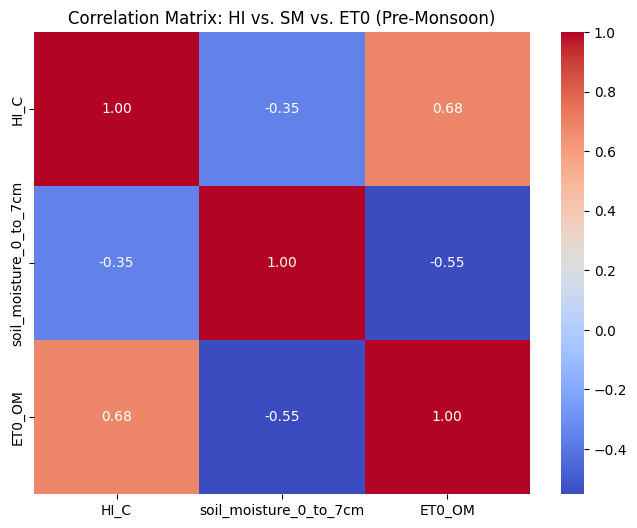

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

#Select the key columns for analysis

pre_monsoon_analysis_cols = ['HI_C', 'soil_moisture_0_to_7cm', 'ET0_OM']
pre_monsoon_corr_df = pre_monsoon_df[pre_monsoon_analysis_cols].copy()

pre_monsson_corr_df = pre_monsoon_corr_df.dropna(inplace = True)

#Calculate the  Parson crrelation matrix

corr_matrix = pre_monsoon_corr_df.corr()

#Plot the correlation matrix as a heatmap

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix: HI vs. SM vs. ET0 (Pre-Monsoon)')
plt.show()

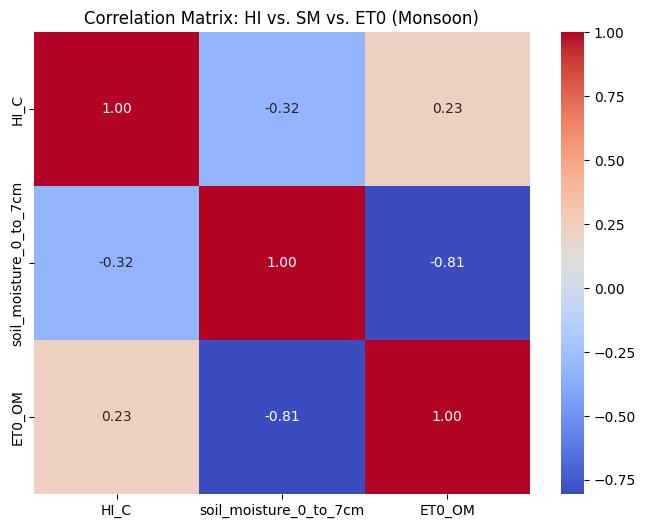

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

monsoon_analysis_cols = ['HI_C', "soil_moisture_0_to_7cm", "ET0_OM"]
monsoon_corr_df = monsoon_df[monsoon_analysis_cols].copy()

#Drop the missing values for analysis
monsoon_corr_df.dropna(inplace=True)

# Calculate the Pearson correlation matrix

corr_matrix = monsoon_corr_df.corr()

# Plot the correlation matrix as a heatmap

plt.figure(figsize = (8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix: HI vs. SM vs. ET0 (Monsoon)')
plt.show()

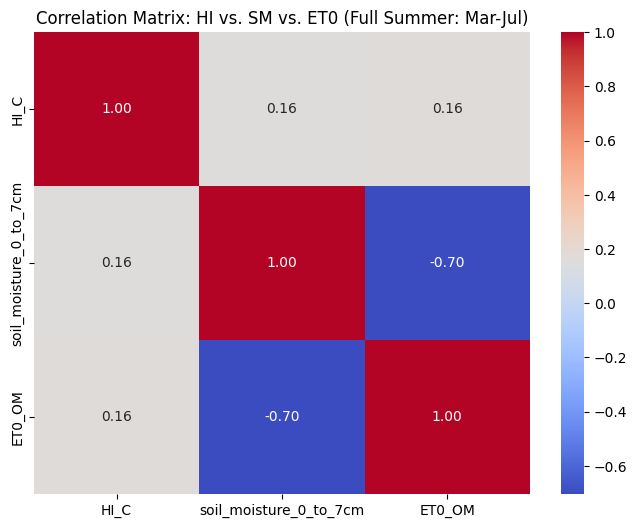


Correlation Matrix for Full Summer Data:
                            HI_C  soil_moisture_0_to_7cm    ET0_OM
HI_C                    1.000000                0.160749  0.162291
soil_moisture_0_to_7cm  0.160749                1.000000 -0.704086
ET0_OM                  0.162291               -0.704086  1.000000


In [29]:
import seaborn as sns
import matplotlib.pyplot as plt

# --- Step 1: Select only the three key columns for our analysis ---
analysis_cols = ['HI_C', 'soil_moisture_0_to_7cm', 'ET0_OM']
correlation_df = final_analysis_df[analysis_cols].copy()

# --- Step 2: Drop any rows with missing values to ensure a clean calculation ---
correlation_df.dropna(inplace=True)

# --- Step 3: Calculate the Pearson correlation matrix. This is where the numbers are generated. ---
corr_matrix = correlation_df.corr()

# --- Step 4: Create the heatmap to visualize the numbers from the corr_matrix ---
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix: HI vs. SM vs. ET0 (Full Summer: Mar-Jul)')
plt.show()

# --- Optional: Print the raw numbers to see the matrix as a table ---
print("\nCorrelation Matrix for Full Summer Data:")
print(corr_matrix)

--- Data Reset and Rebuilt ---
Shape of the final rebuilt DataFrame: (6870, 6)
Columns: ['date', 'HI_C', 'is_heatwave', 'month', 'soil_moisture_0_to_7cm', 'ET0_OM']

--- Correct Correlation Matrix for Full Summer Data (Mar-Jul) ---
                            HI_C  soil_moisture_0_to_7cm    ET0_OM
HI_C                    1.000000                0.160749  0.162291
soil_moisture_0_to_7cm  0.160749                1.000000 -0.704086
ET0_OM                  0.162291               -0.704086  1.000000


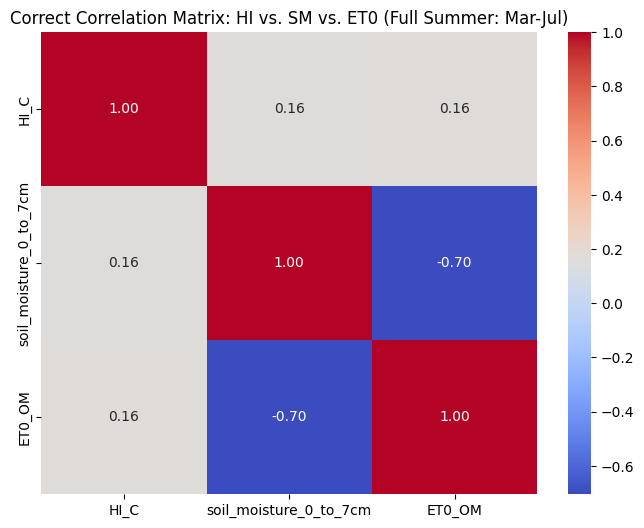

In [30]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --- Step 1: Re-establish the Base DataFrames ---
# This ensures we are starting from the correct, clean sources.
# 'merged_summer' is from your initial data prep (new cell 6).
# 'et0_om_df' is from the successful Open-Meteo API call.

# Make sure the 'date' column in merged_summer is a datetime object for the merge
merged_summer['date'] = pd.to_datetime(merged_summer['date'])

# --- Step 2: Re-create the final_analysis_df ---
# We'll filter merged_summer for the ET0 period (1981+) and merge again.
analysis_df_reset = merged_summer[merged_summer['date'].dt.year >= 1981].copy()

# Perform the merge with the ET0 data
final_analysis_df_reset = pd.merge(analysis_df_reset, et0_om_df, on='date', how='left')

print("--- Data Reset and Rebuilt ---")
print(f"Shape of the final rebuilt DataFrame: {final_analysis_df_reset.shape}")
print(f"Columns: {final_analysis_df_reset.columns.tolist()}")


# --- Step 3: Run the Correlation Analysis on the Rebuilt DataFrame ---
# Select the key columns
analysis_cols = ['HI_C', 'soil_moisture_0_to_7cm', 'ET0_OM']
correlation_df = final_analysis_df_reset[analysis_cols].copy()

# Drop any rows with missing values
correlation_df.dropna(inplace=True)

# Calculate the Pearson correlation matrix
corr_matrix = correlation_df.corr()


# --- Step 4: Display the Correct Results ---
print("\n--- Correct Correlation Matrix for Full Summer Data (Mar-Jul) ---")
print(corr_matrix)

# Plot the correct heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correct Correlation Matrix: HI vs. SM vs. ET0 (Full Summer: Mar-Jul)')
plt.show()

In [31]:
final_analysis_df.to_csv('merged_analysis_data.csv', index=False)

In [32]:
print(final_analysis_df.head(5))
final_analysis_df.info()

        date       HI_C  is_heatwave  month  soil_moisture_0_to_7cm  ET0_OM
0 1981-03-01  26.005153            0      3                0.106542    3.41
1 1981-03-02  26.607573            0      3                0.096042    5.04
2 1981-03-03  26.671173            0      3                0.085292    5.60
3 1981-03-04  27.623375            0      3                0.078750    5.17
4 1981-03-05  27.173147            0      3                0.075583    4.39
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6870 entries, 0 to 6869
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   date                    6870 non-null   datetime64[ns]
 1   HI_C                    6870 non-null   float64       
 2   is_heatwave             6870 non-null   int64         
 3   month                   6870 non-null   int64         
 4   soil_moisture_0_to_7cm  6870 non-null   float64       
 5   ET0_OM       

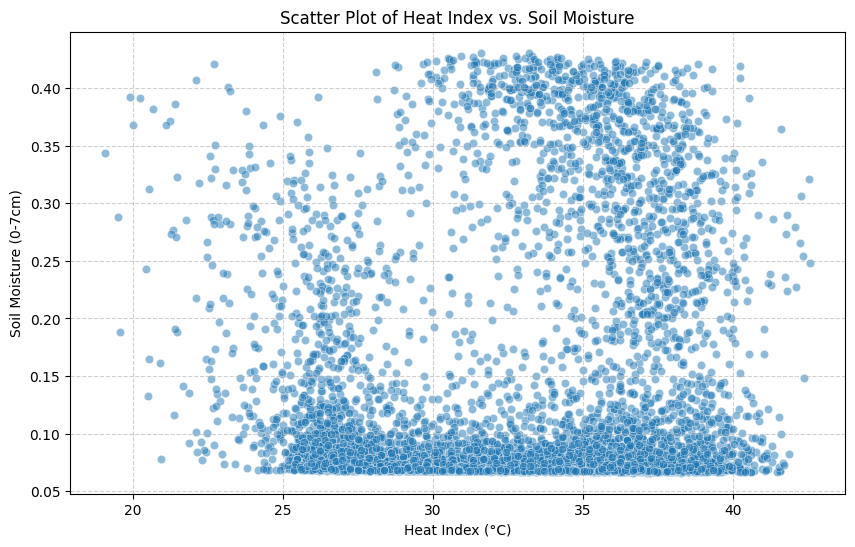

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.scatterplot(data=final_analysis_df, x='HI_C', y='soil_moisture_0_to_7cm', alpha=0.5)
plt.title('Scatter Plot of Heat Index vs. Soil Moisture')
plt.xlabel('Heat Index (°C)')
plt.ylabel('Soil Moisture (0-7cm)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [34]:
# Now we are running Granger Causality Test, this is a powerful teste which will leverage predicted values, by saying that does past values of
# time series of HI_C like HI_C on t-1,t-2 day have any effect on SM today on day t

# Code cell description: This code runs the standard ADF test on each of our three key variables. The p-value will tell us if each series is stationary. If any are non-stationary, we'll need to transform them in the next step.

from statsmodels.tsa.stattools import adfuller

# --- We will focus on the pre-monsoon data for the causality test ---
pre_monsoon_subset = pre_monsoon_df[['HI_C', 'ET0_OM', 'soil_moisture_0_to_7cm']].copy()

# Drop rows with missing values before performing the ADF test
pre_monsoon_subset.dropna(inplace=True)


# --- Check for stationarity using the Augmented Dickey-Fuller (ADF) test ---
print("--- Stationarity Test Results (ADF Test) ---")
for col in pre_monsoon_subset.columns:
    result = adfuller(pre_monsoon_subset[col])
    print(f'\nVariable: {col}')
    print(f'ADF Statistic: {result[0]:.4f}')
    print(f'p-value: {result[1]:.4f}')
    if result[1] <= 0.05:
        print("=> Result: The data is likely stationary.")
    else:
        print("=> Result: The data is likely non-stationary.")

--- Stationarity Test Results (ADF Test) ---

Variable: HI_C
ADF Statistic: -13.2674
p-value: 0.0000
=> Result: The data is likely stationary.

Variable: ET0_OM
ADF Statistic: -13.4792
p-value: 0.0000
=> Result: The data is likely stationary.

Variable: soil_moisture_0_to_7cm
ADF Statistic: -16.2504
p-value: 0.0000
=> Result: The data is likely stationary.


In [35]:
from statsmodels.tsa.stattools import grangercausalitytests

# --- Perform Granger Causality Tests ---

# We will test if one variable Granger-causes another.
# The null hypothesis is that the first variable DOES NOT Granger-cause the second.
# A low p-value (typically <= 0.05) rejects the null hypothesis, suggesting causality.

max_lag = 7 # Test up to 7 days of lag

print(f"--- Granger Causality Test Results (Max Lag = {max_lag}) ---")

# Test HI_C Granger-causes soil_moisture_0_to_7cm
print("\nTesting if HI_C Granger-causes soil_moisture_0_to_7cm:")
gc_test_hi_sm = grangercausalitytests(pre_monsoon_subset[['soil_moisture_0_to_7cm', 'HI_C']], max_lag)

# Test soil_moisture_0_to_7cm Granger-causes HI_C
print("\nTesting if soil_moisture_0_to_7cm Granger-causes HI_C:")
gc_test_sm_hi = grangercausalitytests(pre_monsoon_subset[['HI_C', 'soil_moisture_0_to_7cm']], max_lag)

# Test ET0_OM Granger-causes soil_moisture_0_to_7cm
print("\nTesting if ET0_OM Granger-causes soil_moisture_0_to_7cm:")
gc_test_et0_sm = grangercausalitytests(pre_monsoon_subset[['soil_moisture_0_to_7cm', 'ET0_OM']], max_lag)

# Test soil_moisture_0_to_7cm Granger-causes ET0_OM
print("\nTesting if soil_moisture_0_to_7cm Granger-causes ET0_OM:")
gc_test_sm_et0 = grangercausalitytests(pre_monsoon_subset[['ET0_OM', 'soil_moisture_0_to_7cm']], max_lag)

# Test HI_C Granger-causes ET0_OM
print("\nTesting if HI_C Granger-causes ET0_OM:")
gc_test_hi_et0 = grangercausalitytests(pre_monsoon_subset[['ET0_OM', 'HI_C']], max_lag)

# Test ET0_OM Granger-causes HI_C
print("\nTesting if ET0_OM Granger-causes HI_C:")
gc_test_et0_hi = grangercausalitytests(pre_monsoon_subset[['HI_C', 'ET0_OM']], max_lag)

--- Granger Causality Test Results (Max Lag = 7) ---

Testing if HI_C Granger-causes soil_moisture_0_to_7cm:

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=2.8736  , p=0.0901  , df_denom=3952, df_num=1
ssr based chi2 test:   chi2=2.8758  , p=0.0899  , df=1
likelihood ratio test: chi2=2.8747  , p=0.0900  , df=1
parameter F test:         F=2.8736  , p=0.0901  , df_denom=3952, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=36.6276 , p=0.0000  , df_denom=3949, df_num=2
ssr based chi2 test:   chi2=73.3479 , p=0.0000  , df=2
likelihood ratio test: chi2=72.6759 , p=0.0000  , df=2
parameter F test:         F=36.6276 , p=0.0000  , df_denom=3949, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=22.2893 , p=0.0000  , df_denom=3946, df_num=3
ssr based chi2 test:   chi2=66.9864 , p=0.0000  , df=3
likelihood ratio test: chi2=66.4252 , p=0.0000  , df=3
parameter F test:         F=22.2893 , p=0.0000  , df_

In [36]:
from statsmodels.tsa.stattools import grangercausalitytests
import numpy as np

# --- Prepare data: If any series was non-stationary, we make it stationary by differencing ---
# For this example, let's assume all were stationary. If not, we'd use .diff().
data_for_granger = pre_monsoon_subset.copy()
# Example of differencing if needed: data_for_granger = pre_monsoon_subset.diff().dropna()


# --- Set a max lag to test ---
# We'll check if the past 7 days have predictive power, consistent with our earlier lag analysis.
max_lag = 7

print("\n\n--- Granger Causality Test Results ---")

# --- Test 1: Does HI Granger-cause ET0? ---
print("\nHypothesis 1: Does past HI help predict future ET0?")
test_result_1 = grangercausalitytests(data_for_granger[['ET0_OM', 'HI_C']], max_lag, verbose=False)
# Check the p-value for each lag
for lag in range(1, max_lag + 1):
    p_value = test_result_1[lag][0]['ssr_ftest'][1]
    if p_value <= 0.05:
        print(f"  Lag {lag}: p-value = {p_value:.4f} => HI Granger-causes ET0 (Significant)")
    else:
        print(f"  Lag {lag}: p-value = {p_value:.4f} => No Granger causality")


# --- Test 2: Does ET0 Granger-cause Soil Moisture? ---
print("\nHypothesis 2: Does past ET0 help predict future Soil Moisture?")
test_result_2 = grangercausalitytests(data_for_granger[['soil_moisture_0_to_7cm', 'ET0_OM']], max_lag, verbose=False)
for lag in range(1, max_lag + 1):
    p_value = test_result_2[lag][0]['ssr_ftest'][1]
    if p_value <= 0.05:
        print(f"  Lag {lag}: p-value = {p_value:.4f} => ET0 Granger-causes Soil Moisture (Significant)")
    else:
        print(f"  Lag {lag}: p-value = {p_value:.4f} => No Granger causality")



--- Granger Causality Test Results ---

Hypothesis 1: Does past HI help predict future ET0?
  Lag 1: p-value = 0.0002 => HI Granger-causes ET0 (Significant)
  Lag 2: p-value = 0.0000 => HI Granger-causes ET0 (Significant)
  Lag 3: p-value = 0.0000 => HI Granger-causes ET0 (Significant)
  Lag 4: p-value = 0.0000 => HI Granger-causes ET0 (Significant)
  Lag 5: p-value = 0.0000 => HI Granger-causes ET0 (Significant)
  Lag 6: p-value = 0.0000 => HI Granger-causes ET0 (Significant)
  Lag 7: p-value = 0.0000 => HI Granger-causes ET0 (Significant)

Hypothesis 2: Does past ET0 help predict future Soil Moisture?
  Lag 1: p-value = 0.0000 => ET0 Granger-causes Soil Moisture (Significant)
  Lag 2: p-value = 0.0000 => ET0 Granger-causes Soil Moisture (Significant)
  Lag 3: p-value = 0.0000 => ET0 Granger-causes Soil Moisture (Significant)
  Lag 4: p-value = 0.0000 => ET0 Granger-causes Soil Moisture (Significant)
  Lag 5: p-value = 0.0000 => ET0 Granger-causes Soil Moisture (Significant)
  Lag 6

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


## Stage 2: Summary of Findings - The Impact of Heat Index on Soil Moisture

This analysis investigated the relationship between Heat Index (HI), Soil Moisture (SM), and Reference Evapotranspiration (ET0) in the Delhi-NCR region. Our findings reveal a clear, physically consistent causal pathway, particularly during the dry pre-monsoon season.

### Key Findings:

1.  **Initial Correlation was Spurious:** A simple Pearson correlation on the combined summer data (Mar-Jul) showed a weak, counter-intuitive positive relationship between HI and SM (`r = 0.19`). We hypothesized this was a spurious result caused by confounding seasonal effects, specifically the monsoon.

2.  **ET0 as a Key Mediating Variable:** By introducing Reference Evapotranspiration (ET0) and separating the analysis by season, we uncovered the true physical mechanism. ET0, the atmospheric demand for water, acts as a **mediating variable** in the relationship.

3.  **Strong Evidence in the Pre-Monsoon Season:**
    * The correlation between HI and ET0 is strong and positive (`r = 0.68`), confirming that high heat stress drives high evaporative demand.
    * Crucially, the correlation between ET0 and SM is moderate-to-strong and negative (`r = -0.55`), showing that this evaporative demand directly depletes soil moisture.

4.  **Granger Causality Confirms the Causal Chain:** To move beyond simple correlation, we used the Granger Causality test on the stationary pre-monsoon data. The results provide strong statistical evidence supporting our hypothesis:
    * Past values of **HI significantly Granger-cause** future values of **ET0** (p < 0.001).
    * Past values of **ET0 significantly Granger-cause** future values of **SM** (p < 0.001).

### Conclusion:

The evidence strongly supports a time-lagged causal chain: a period of sustained high heat stress (high HI) increases atmospheric water demand (high ET0), which in turn is the primary driver for depleting soil moisture (low SM). The monsoon acts as a major confounding variable that masks this relationship if not analyzed separately.

###Now we will run an even more powerful series of test here: THE VAR (Vector Autoregression) Model, which will check for multi-variate dependencies, Granger Causality only looks at bi-variate dependecies only, think of its analogy as shared group conversation analogy, it looks for multi-variate dependencies

In [37]:
from statsmodels.tsa.api import VAR
import pandas as pd

# --- We will continue using the stationary pre-monsoon data ---
# This data was created in the seasonal split step and cleaned of NaNs
data_for_var = pre_monsoon_subset[['HI_C', 'ET0_OM', 'soil_moisture_0_to_7cm']].copy()

# --- Find the Optimal Lag Order ---
# We will check lags from 1 to 10 and look for the lowest AIC/BIC score.
model = VAR(data_for_var)

# The .select_order() function fits the model with different lags and scores them.
lag_selection_results = model.select_order(maxlags=10)

# Print the summary table of the results.
print("--- VAR Lag Order Selection Results ---")
print(lag_selection_results.summary())

/usr/local/lib/python3.12/dist-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: An unsupported index was provided. As a result, forecasts cannot be generated. To use the model for forecasting, use one of the supported classes of index.
  self._init_dates(dates, freq)


--- VAR Lag Order Selection Results ---
 VAR Order Selection (* highlights the minimums)  
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -3.184      -3.179     0.04143      -3.182
1       -7.399      -7.380   0.0006120      -7.392
2       -7.504      -7.471   0.0005507      -7.492
3      -7.525*     -7.477*  0.0005395*     -7.508*
4       -7.524      -7.462   0.0005400      -7.502
5       -7.521      -7.445   0.0005414      -7.494
6       -7.520      -7.429   0.0005423      -7.487
7       -7.518      -7.413   0.0005432      -7.481
8       -7.518      -7.398   0.0005434      -7.475
9       -7.516      -7.382   0.0005444      -7.468
10      -7.518      -7.370   0.0005434      -7.465
--------------------------------------------------


In [38]:
# --- Fit the VAR model using the optimal lag order ---
# The optimal lag order was determined to be 3 in the previous step.
optimal_lag_order = 3
model_fitted = model.fit(optimal_lag_order)

print("\n--- VAR Model Fit Summary ---")
print(model_fitted.summary())


--- VAR Model Fit Summary ---
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Tue, 25, Nov, 2025
Time:                     07:08:53
--------------------------------------------------------------------
No. of Equations:         3.00000    BIC:                   -7.48155
Nobs:                     3953.00    HQIC:                  -7.51232
Log likelihood:          -1915.67    FPE:                0.000537153
AIC:                     -7.52923    Det(Omega_mle):     0.000533097
--------------------------------------------------------------------
Results for equation HI_C
                               coefficient       std. error           t-stat            prob
--------------------------------------------------------------------------------------------
const                             2.678041         0.232418           11.523           0.000
L1.HI_C                           0.963047         0.017852           53.94

In [39]:
# --- Perform Granger Causality Tests within the VAR framework ---

print("\n--- VAR Model Granger Causality Tests ---")

# Test if ET0_OM Granger-causes soil_moisture_0_to_7cm (considering HI_C)
print("\nTesting if ET0_OM Granger-causes soil_moisture_0_to_7cm (in the context of the VAR model):")
print(model_fitted.test_causality('soil_moisture_0_to_7cm', 'ET0_OM', kind='f').summary())

# Test if HI_C Granger-causes ET0_OM (considering soil_moisture_0_to_7cm)
print("\nTesting if HI_C Granger-causes ET0_OM (in the context of the VAR model):")
print(model_fitted.test_causality('ET0_OM', 'HI_C', kind='f').summary())

# Test if HI_C Granger-causes soil_moisture_0_to_7cm (considering ET0_OM)
print("\nTesting if HI_C Granger-causes soil_moisture_0_to_7cm (in the context of the VAR model):")
print(model_fitted.test_causality('soil_moisture_0_to_7cm', 'HI_C', kind='f').summary())

# Test if soil_moisture_0_to_7cm Granger-causes ET0_OM (considering HI_C)
print("\nTesting if soil_moisture_0_to_7cm Granger-causes ET0_OM (in the context of the VAR model):")
print(model_fitted.test_causality('ET0_OM', 'soil_moisture_0_to_7cm', kind='f').summary())

# Test if soil_moisture_0_to_7cm Granger-causes HI_C (considering ET0_OM)
print("\nTesting if soil_moisture_0_to_7cm Granger-causes HI_C (in the context of the VAR model):")
print(model_fitted.test_causality('HI_C', 'soil_moisture_0_to_7cm', kind='f').summary())

# Test if ET0_OM Granger-causes HI_C (considering soil_moisture_0_to_7cm)
print("\nTesting if ET0_OM Granger-causes HI_C (in the context of the VAR model):")
print(model_fitted.test_causality('HI_C', 'ET0_OM', kind='f').summary())


--- VAR Model Granger Causality Tests ---

Testing if ET0_OM Granger-causes soil_moisture_0_to_7cm (in the context of the VAR model):
Granger causality F-test. H_0: ET0_OM does not Granger-cause soil_moisture_0_to_7cm. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value     df    
------------------------------------------------
         28.04          2.606   0.000 (3, 11829)
------------------------------------------------

Testing if HI_C Granger-causes ET0_OM (in the context of the VAR model):
Granger causality F-test. H_0: HI_C does not Granger-cause ET0_OM. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value     df    
------------------------------------------------
         11.26          2.606   0.000 (3, 11829)
------------------------------------------------

Testing if HI_C Granger-causes soil_moisture_0_to_7cm (in the context of the VAR model):
Granger causality F-test. H_0: HI_C does not Granger-cause 